In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names

print("Original shape:", X.shape)
print("Features:", feature_names)

Original shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [2]:
#Step 2: Standardize the data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled mean:", X_scaled.mean(axis=0))
print("Scaled standard deviation:", X_scaled.std(axis=0))

Scaled mean: [-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]
Scaled standard deviation: [1. 1. 1. 1.]


In [3]:
#Apply PCA
# Reduce four features to two components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:",
      pca.explained_variance_ratio_)

print("Total variance retained:",
      pca.explained_variance_ratio_.sum())

Reduced shape: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total variance retained: 0.9581320720000166


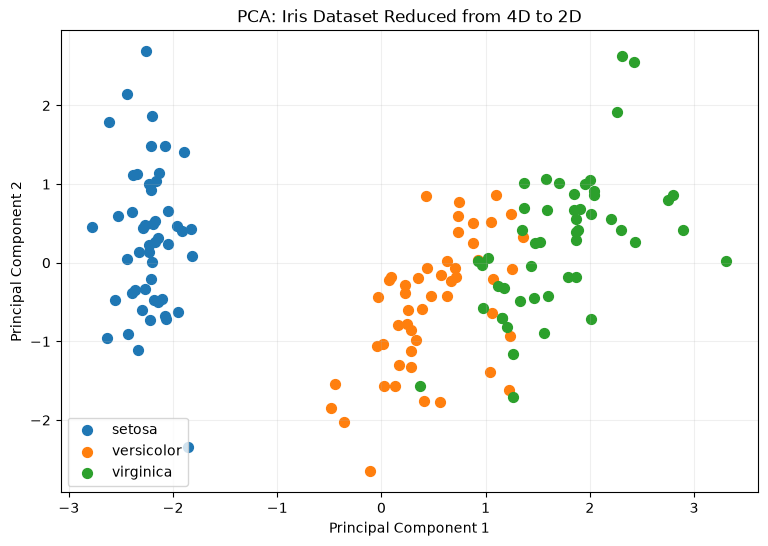

In [4]:
#Step 4: Visualize the reduced data
plt.figure(figsize=(9, 6))

for class_id, species in enumerate(iris.target_names):
    mask = y == class_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Iris Dataset Reduced from 4D to 2D")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
#Step 5: Understand the explained variance
# Explained variance of each component
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

for i, ratio in enumerate(explained_variance, start=1):
    print(f"PC{i}: {ratio:.4f} ({ratio * 100:.2f}%)")

print("Cumulative variance:")
print(cumulative_variance)

Cumulative variance:
[0.72962445 0.95813207]


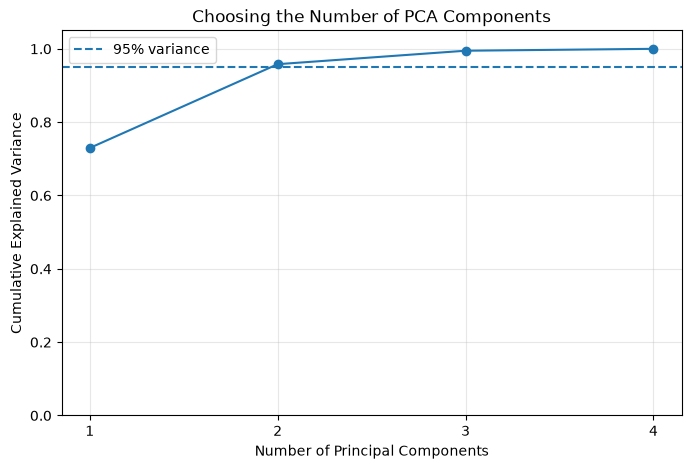

In [6]:
# Fit PCA without reducing the number of components
pca_full = PCA()

pca_full.fit(X_scaled)

cumulative = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative) + 1),
    cumulative,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Choosing the Number of PCA Components")
plt.xticks(range(1, len(cumulative) + 1))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
#9. PCA loadings: understanding the new components
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=["PC1", "PC2"]
)

print(loadings.round(3))

                     PC1    PC2
sepal length (cm)  0.521  0.377
sepal width (cm)  -0.269  0.923
petal length (cm)  0.580  0.024
petal width (cm)   0.565  0.067
